# 사출성형 데이터 EDA와 불량 유형별 분석

원본 `moldset_labeled.csv`의 `Reason` 열을 사용한다. 불량 유형은 실제로 세 가지다.

- 가스
- 미성형
- 초기허용불량

단순 전체 평균 비교뿐 아니라 각 불량의 앞뒤 정상 제품과도 비교한다. 이렇게 해야 제품 종류와 생산 시점 차이를 불량 원인으로 잘못 해석할 가능성을 줄일 수 있다.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pointbiserialr, rankdata

warnings.filterwarnings('ignore', category=RuntimeWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['font.family'] = ['Malgun Gothic', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
SOURCE = ROOT / 'data' / 'original' / 'moldset_labeled.csv'
REPORT_DIR = ROOT / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'
TABLE_DIR = REPORT_DIR / 'tables'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(SOURCE)
df['TimeStamp'] = pd.to_datetime(df['TimeStamp'], errors='coerce')
df['Reason'] = df['Reason'].fillna('정상')
reason_order = ['정상', '가스', '미성형', '초기허용불량']
df['Reason'] = pd.Categorical(df['Reason'], categories=reason_order, ordered=True)

process_features = [
    'Injection_Time', 'Filling_Time', 'Plasticizing_Time', 'Cycle_Time', 'Clamp_Close_Time',
    'Cushion_Position', 'Plasticizing_Position', 'Clamp_Open_Position', 'Max_Injection_Speed',
    'Max_Screw_RPM', 'Average_Screw_RPM', 'Max_Injection_Pressure',
    'Max_Switch_Over_Pressure', 'Max_Back_Pressure', 'Average_Back_Pressure',
    'Barrel_Temperature_1', 'Barrel_Temperature_2', 'Barrel_Temperature_3',
    'Barrel_Temperature_4', 'Barrel_Temperature_5', 'Barrel_Temperature_6',
    'Hopper_Temperature', 'Mold_Temperature_3', 'Mold_Temperature_4'
]
process_features = [c for c in process_features if c in df.columns and df[c].nunique(dropna=False) > 1]
df.shape, process_features

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\hayeon\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


((2607, 47),
 ['Injection_Time',
  'Filling_Time',
  'Plasticizing_Time',
  'Cycle_Time',
  'Clamp_Close_Time',
  'Cushion_Position',
  'Plasticizing_Position',
  'Clamp_Open_Position',
  'Max_Injection_Speed',
  'Max_Screw_RPM',
  'Average_Screw_RPM',
  'Max_Injection_Pressure',
  'Max_Switch_Over_Pressure',
  'Max_Back_Pressure',
  'Average_Back_Pressure',
  'Barrel_Temperature_1',
  'Barrel_Temperature_2',
  'Barrel_Temperature_3',
  'Barrel_Temperature_4',
  'Barrel_Temperature_5',
  'Barrel_Temperature_6',
  'Hopper_Temperature',
  'Mold_Temperature_3',
  'Mold_Temperature_4'])

## 1. 데이터 상태

원본은 2,607개 생산 기록과 24개 유효 공정변수를 포함한다. 먼저 결측, 중복, 불량 유형 수를 확인한다.

In [2]:
quality = pd.DataFrame([{
    '전체 행': len(df),
    '공정변수 수': len(process_features),
    '공정변수 결측 셀': int(df[process_features].isna().sum().sum()),
    '완전 중복 행': int(df.duplicated().sum()),
    '시작 시각': df['TimeStamp'].min(),
    '종료 시각': df['TimeStamp'].max()
}])
quality.to_csv(TABLE_DIR / 'original_data_quality.csv', index=False, encoding='utf-8-sig')
quality

,전체 행,공정변수 수,공정변수 결측 셀,완전 중복 행,시작 시각,종료 시각
0,2607,24,0,0,2020-10-16 04:57:47,2020-10-27 02:22:07


In [3]:
reason_counts = pd.crosstab(df['Reason'], df['PART_NAME'], dropna=False).reindex(reason_order).fillna(0).astype(int)
reason_counts['합계'] = reason_counts.sum(axis=1)
reason_counts.to_csv(TABLE_DIR / 'original_reason_counts.csv', encoding='utf-8-sig')
reason_counts

PART_NAME,CN7 W/S SIDE MLD'G LH,CN7 W/S SIDE MLD'G RH,"RG3 MOLD'G W/SHLD, LH","RG3 MOLD'G W/SHLD, RH",합계
Reason,,,,,
정상,703,695,591,566,2555
가스,3,10,0,17,30
미성형,1,3,0,8,12
초기허용불량,5,5,0,0,10


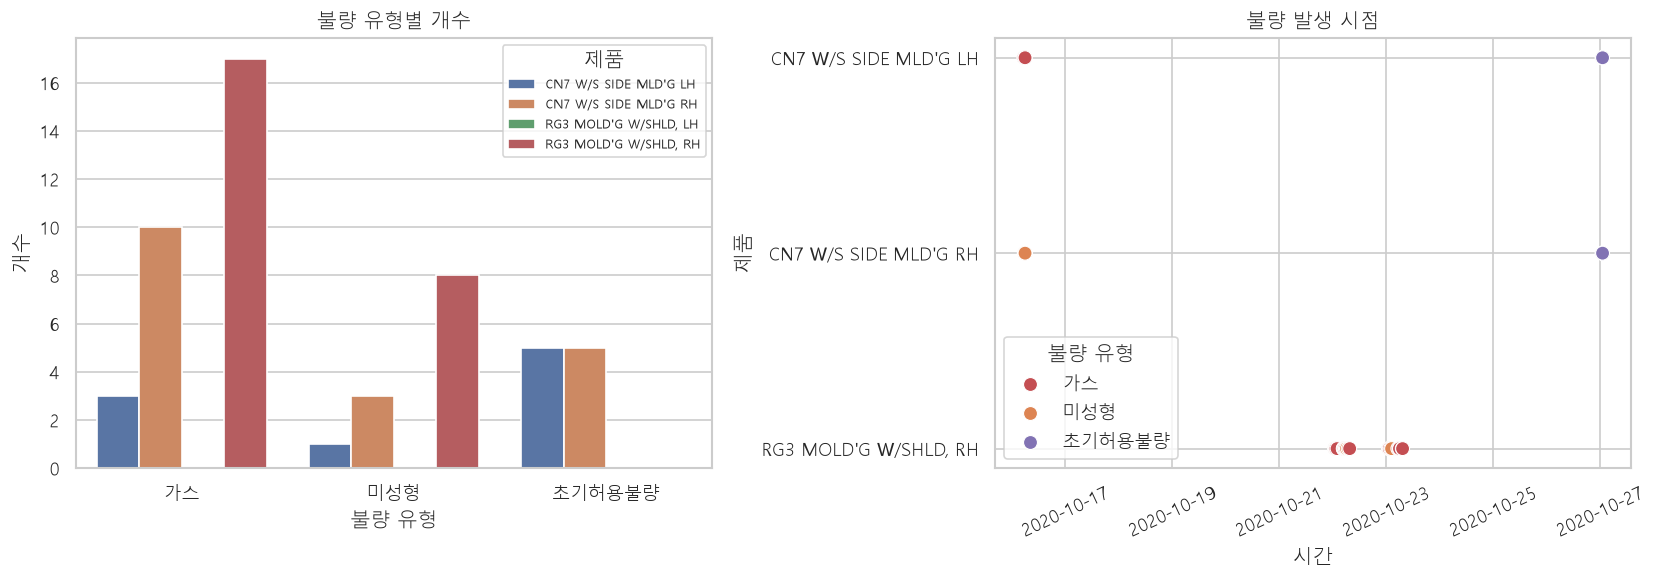

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
counts_long = df.groupby(['Reason', 'PART_NAME'], observed=False).size().reset_index(name='개수')
counts_long = counts_long[counts_long['Reason'] != '정상'].copy()
counts_long['Reason'] = counts_long['Reason'].cat.remove_unused_categories()
sns.barplot(data=counts_long, x='Reason', y='개수', hue='PART_NAME', ax=axes[0])
axes[0].set_title('불량 유형별 개수')
axes[0].set_xlabel('불량 유형')
axes[0].set_ylabel('개수')
axes[0].legend(title='제품', fontsize=8)

bad = df[df['Reason'] != '정상'].copy()
bad['Reason'] = bad['Reason'].cat.remove_unused_categories()
palette = {'가스':'#c44e52', '미성형':'#dd8452', '초기허용불량':'#8172b3'}
sns.scatterplot(data=bad, x='TimeStamp', y='PART_NAME', hue='Reason', palette=palette, s=70, ax=axes[1])
axes[1].set_title('불량 발생 시점')
axes[1].set_xlabel('시간')
axes[1].set_ylabel('제품')
axes[1].tick_params(axis='x', rotation=25)
axes[1].legend(title='불량 유형')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'eda_reason_counts_and_timeline.png', bbox_inches='tight')
plt.show()

## 2. 공정변수 분포

모든 제품을 함께 그린 분포다. 봉우리가 여러 개이면 제품 또는 생산 조건에 따라 값의 중심이 다를 수 있다. 그래서 다음 분석에서는 제품별 표준화를 적용한다.

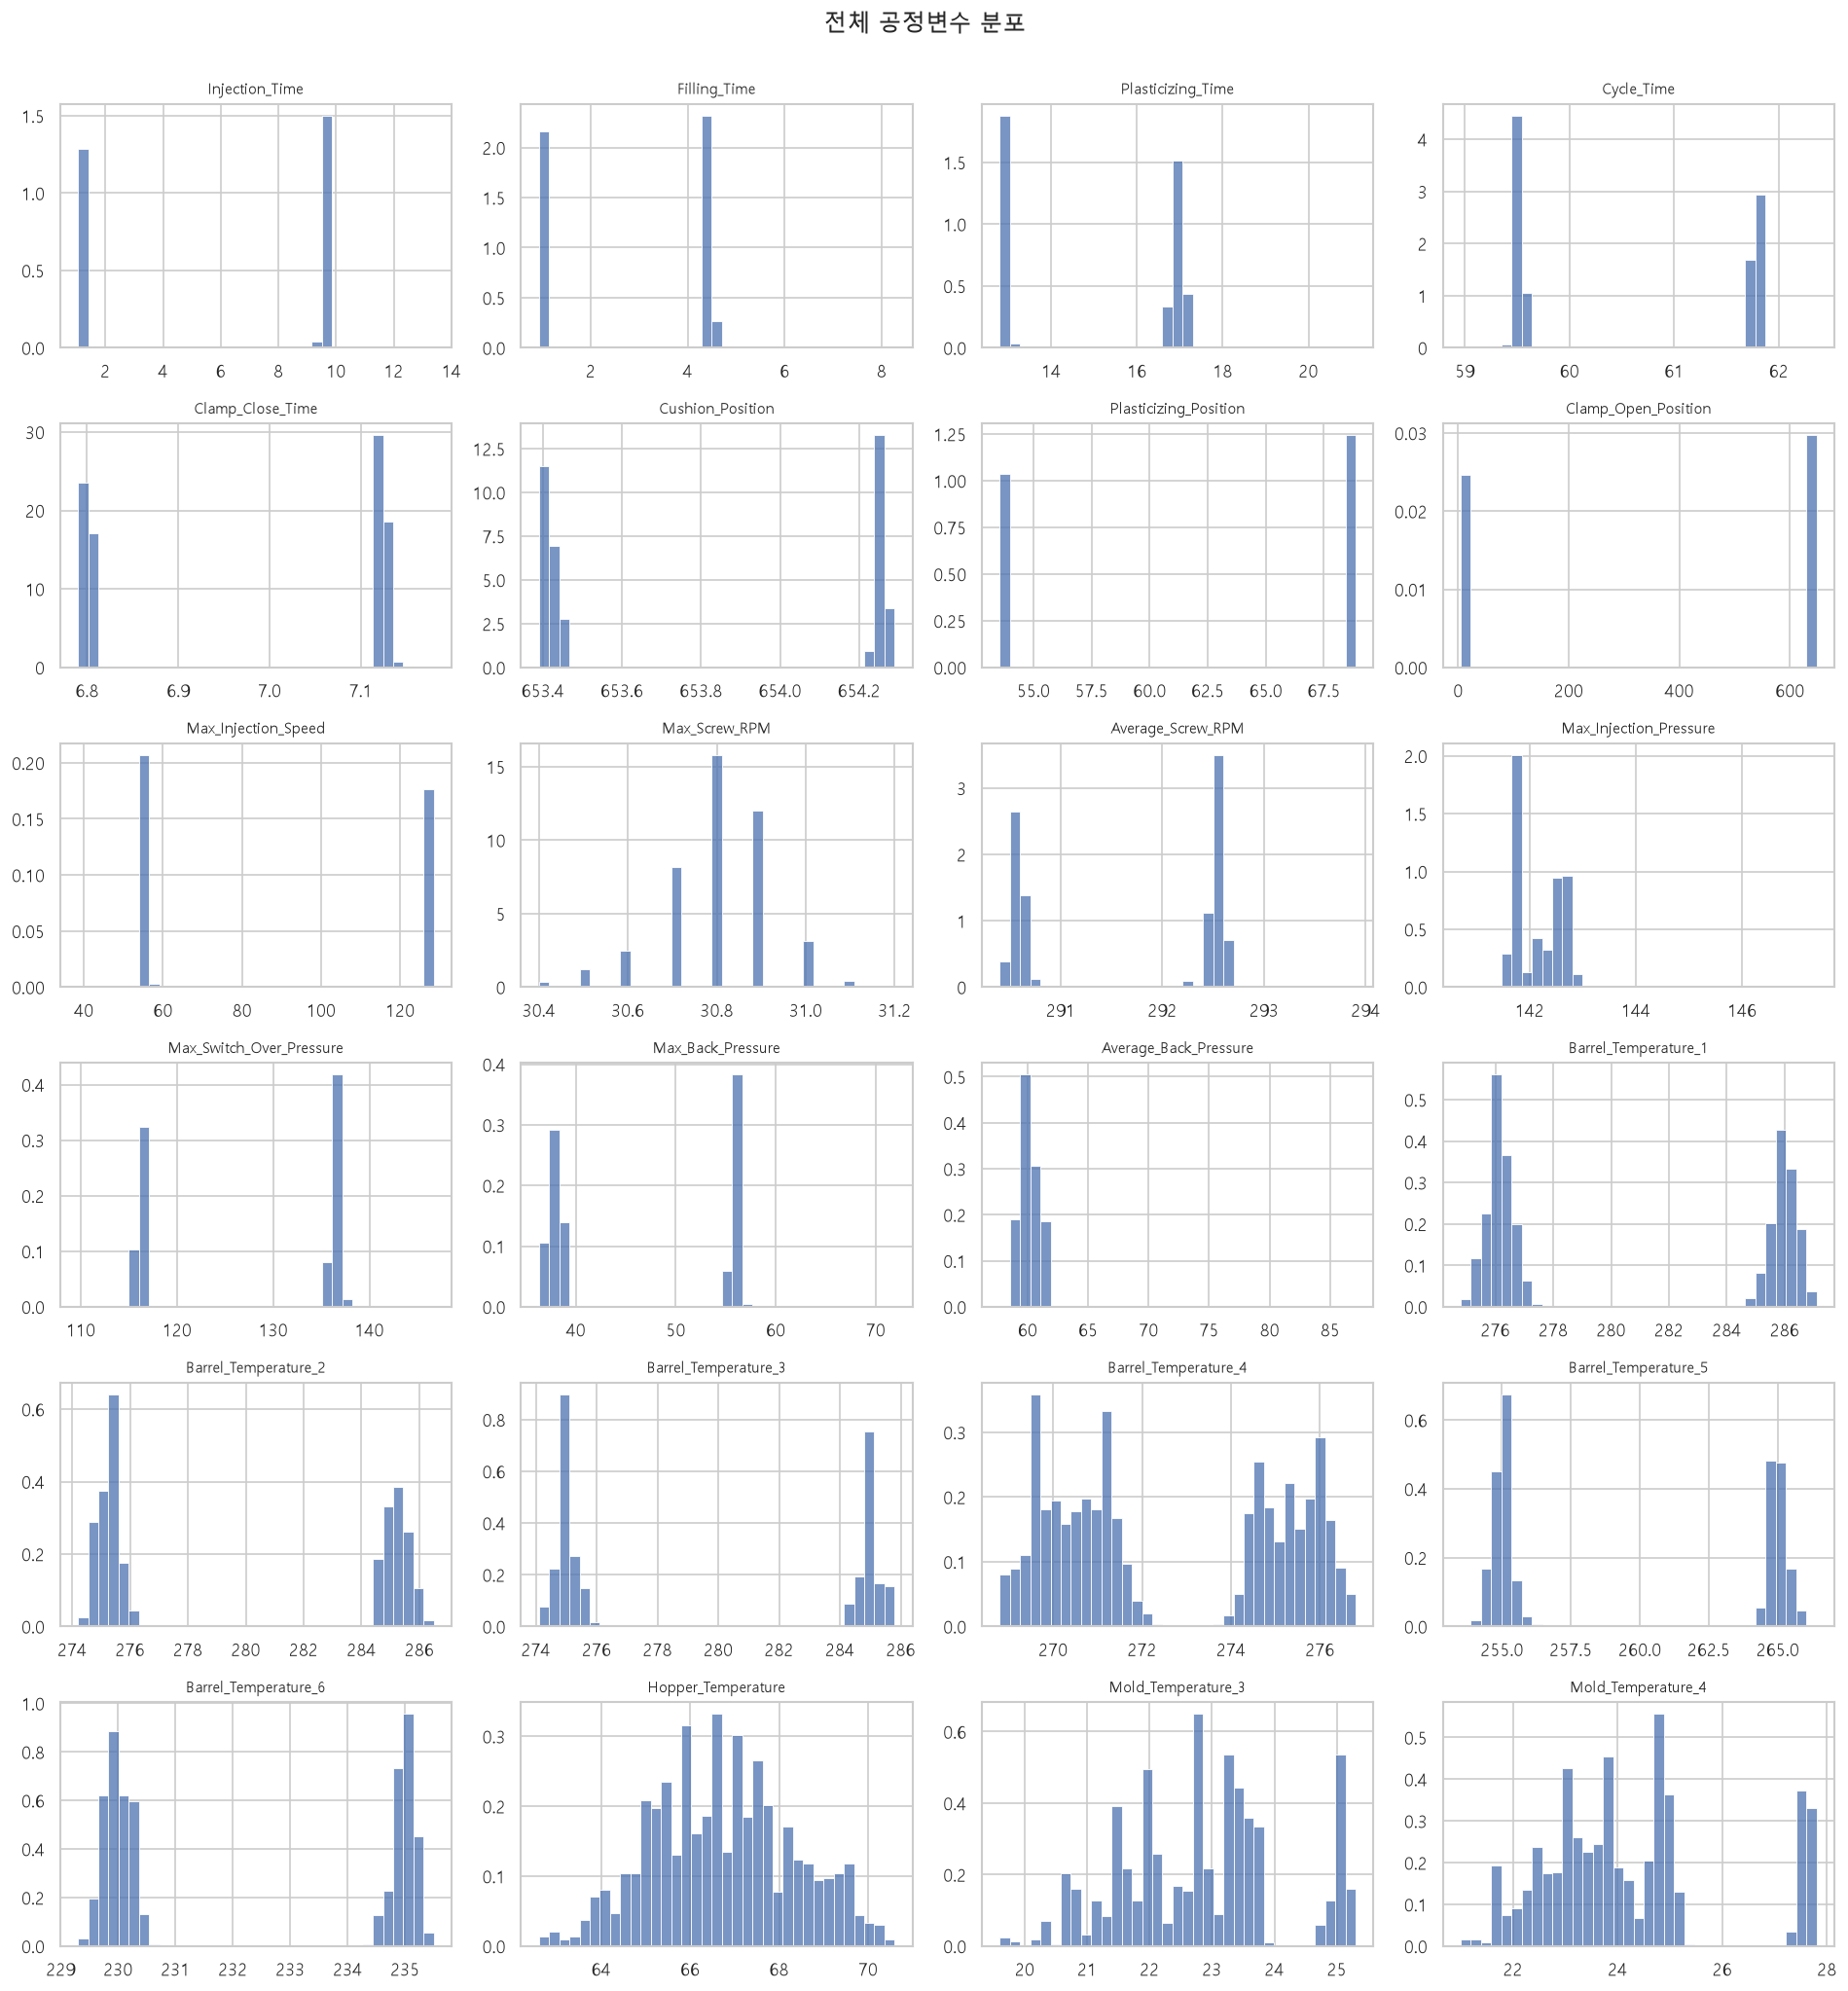

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing,unique
Injection_Time,2607.0,5.711105,4.238696,1.050000,1.060000,1.06,9.520000,9.550000,9.640000,13.390000,0,28
Filling_Time,2607.0,2.858807,1.756242,0.930000,0.930000,0.94,4.410000,4.440000,4.520000,8.270000,0,25
Plasticizing_Time,2607.0,15.139693,2.026422,12.800000,12.850000,12.92,16.780001,17.000000,17.129999,21.100000,0,82
Cycle_Time,2607.0,60.542800,1.125377,58.959999,59.459999,59.52,59.580002,61.779999,61.779999,62.360001,0,28
Clamp_Close_Time,2607.0,6.978470,0.160223,6.790000,6.790000,6.80,7.120000,7.120000,7.130000,7.180000,0,7


In [5]:
summary = df[process_features].describe(percentiles=[.01, .25, .5, .75, .99]).T
summary['missing'] = df[process_features].isna().sum()
summary['unique'] = df[process_features].nunique()
summary.to_csv(TABLE_DIR / 'original_feature_summary.csv', encoding='utf-8-sig')

fig, axes = plt.subplots(6, 4, figsize=(16, 17))
for ax, feature in zip(axes.ravel(), process_features):
    sns.histplot(df[feature], bins=35, ax=ax, color='#4c72b0', stat='density')
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle('전체 공정변수 분포', y=1.002)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'eda_original_feature_distributions.png', bbox_inches='tight')
plt.show()
summary.head()

## 3. 불량 유형과 공정변수의 관계

제품마다 원래 설정 범위가 다르므로 각 `PART_NAME` 안에서 값을 표준화한 뒤 비교한다. 상관계수가 양수면 해당 불량에서 값이 높고, 음수면 낮다. 다른 불량 유형은 비교에서 제외하고 정상과 해당 유형만 비교한다.

In [6]:
z = df.copy()
for feature in process_features:
    group_mean = df.groupby('PART_NAME')[feature].transform('mean')
    group_std = df.groupby('PART_NAME')[feature].transform('std').replace(0, np.nan)
    z[feature] = (df[feature] - group_mean) / group_std

def bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = p[order] * len(p) / np.arange(1, len(p)+1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    out = np.empty_like(adjusted)
    out[order] = np.clip(adjusted, 0, 1)
    return out

def reason_association(frame, reason):
    part = frame[frame['Reason'].isin(['정상', reason])].copy()
    y = (part['Reason'] == reason).astype(int).to_numpy()
    n1, n0 = int(y.sum()), int((1-y).sum())
    rows = []
    for feature in process_features:
        valid = part[feature].notna().to_numpy()
        x, yy = part.loc[valid, feature].to_numpy(float), y[valid]
        if np.unique(x).size <= 1:
            continue
        test = pointbiserialr(yy, x)
        ranks = rankdata(x)
        nn1, nn0 = yy.sum(), (1-yy).sum()
        auc = (ranks[yy==1].sum()-nn1*(nn1+1)/2)/(nn1*nn0)
        rows.append({
            '불량유형': reason, '변수': feature, '상관계수': test.statistic, 'p값': test.pvalue,
            '정상평균_z': x[yy==0].mean(), '불량평균_z': x[yy==1].mean(),
            '방향보정AUC': max(auc, 1-auc), '불량수': int(nn1), '정상수': int(nn0)
        })
    result = pd.DataFrame(rows)
    result['FDR_q값'] = bh_fdr(result['p값'])
    result['절대상관'] = result['상관계수'].abs()
    return result.sort_values('절대상관', ascending=False)

association = pd.concat([reason_association(z, r) for r in reason_order[1:]], ignore_index=True)
association.to_csv(TABLE_DIR / 'original_reason_feature_associations.csv', index=False, encoding='utf-8-sig')
association.groupby('불량유형', sort=False).head(8)

,불량유형,변수,상관계수,p값,정상평균_z,불량평균_z,방향보정AUC,불량수,정상수,FDR_q값,절대상관
0,가스,Clamp_Close_Time,0.076306,1.030130e-04,-0.022424,0.640723,0.688728,30,2555,2.369298e-03,0.076306
1,가스,Plasticizing_Position,0.070301,3.475296e-04,-0.009769,0.647011,0.669426,30,2555,3.996590e-03,0.070301
2,가스,Mold_Temperature_4,0.060245,2.181723e-03,-0.004230,0.556957,0.646699,30,2555,1.672655e-02,0.060245
3,가스,Mold_Temperature_3,0.050180,1.072146e-02,-0.001818,0.465145,0.647025,30,2555,6.164840e-02,0.050180
4,가스,Cushion_Position,-0.038831,4.837572e-02,-0.004434,-0.342891,0.578200,30,2555,2.225283e-01,0.038831
5,가스,Max_Injection_Speed,0.022162,2.600014e-01,0.025417,0.182501,0.507012,30,2555,7.377496e-01,0.022162
6,가스,Barrel_Temperature_4,0.021458,2.754461e-01,-0.001634,0.198116,0.560907,30,2555,7.377496e-01,0.021458
7,가스,Max_Injection_Pressure,-0.021276,2.795523e-01,-0.029344,-0.183310,0.556732,30,2555,7.377496e-01,0.021276
23,미성형,Max_Injection_Speed,0.138471,1.838073e-12,0.025417,1.585284,0.680936,12,2555,4.227569e-11,0.138471
24,미성형,Mold_Temperature_4,0.038989,4.824684e-02,-0.004230,0.564451,0.661742,12,2555,3.846880e-01,0.038989


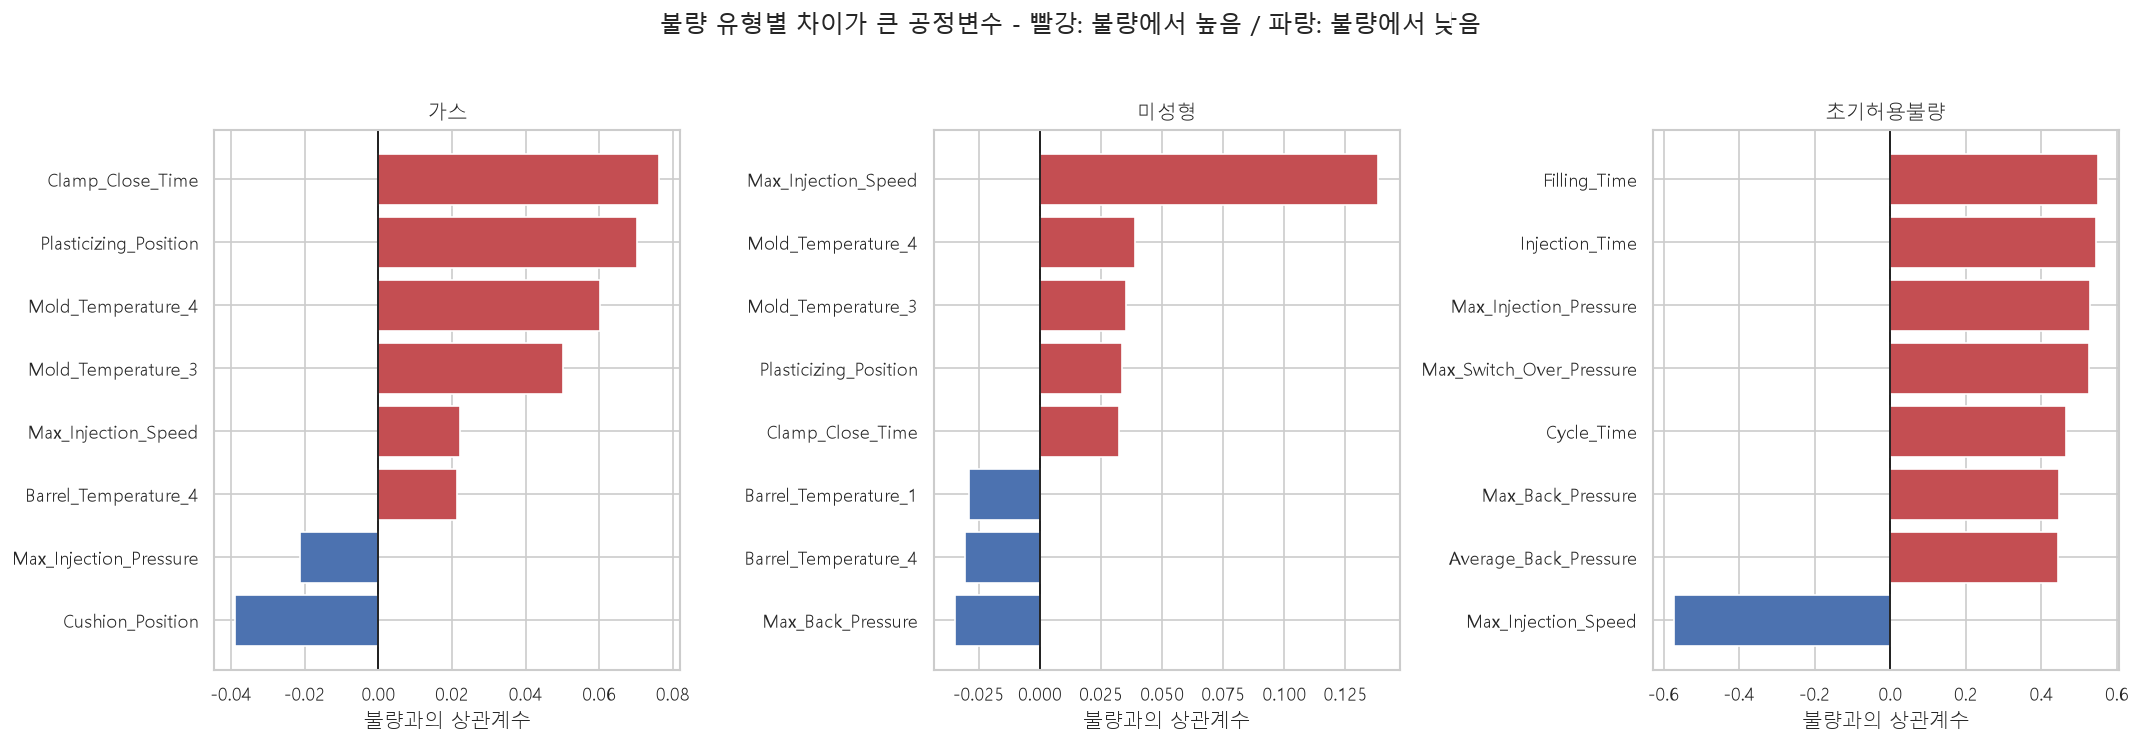

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, reason in zip(axes, reason_order[1:]):
    top = association[association['불량유형'] == reason].head(8).sort_values('상관계수')
    colors = ['#4c72b0' if v < 0 else '#c44e52' for v in top['상관계수']]
    ax.barh(top['변수'], top['상관계수'], color=colors)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(reason)
    ax.set_xlabel('불량과의 상관계수')
fig.suptitle('불량 유형별 차이가 큰 공정변수 - 빨강: 불량에서 높음 / 파랑: 불량에서 낮음', y=1.03)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'eda_reason_top_associations.png', bbox_inches='tight')
plt.show()

## 4. 불량 직전·직후 정상 제품과 비교

전체 정상값과의 차이가 아니라 각 불량 행의 앞뒤 30개 행 중 같은 제품의 정상값과 비교한다. `주변대비편차`가 양수면 주변 정상보다 높고 음수면 낮다. 편차 단위는 해당 제품의 전체 표준편차다. 이 결과를 현장 원인 후보에 더 가깝게 사용한다.

In [8]:
def local_deviations(frame, window=30):
    frame = frame.reset_index(drop=True)
    records = []
    for pos in frame.index[frame['Reason'] != '정상']:
        reason = str(frame.loc[pos, 'Reason'])
        product = frame.loc[pos, 'PART_NAME']
        lo, hi = max(0, pos-window), min(len(frame), pos+window+1)
        neighbors = frame.iloc[lo:hi]
        neighbors = neighbors[(neighbors['Reason'] == '정상') & (neighbors['PART_NAME'] == product)]
        for feature in process_features:
            values = neighbors[feature].dropna().astype(float)
            median = values.median()
            value = float(frame.loc[pos, feature])
            deviation = value-median if np.isfinite(median) else np.nan
            records.append({
                '불량위치': pos, '불량유형': reason, '제품': product, '변수': feature,
                '주변정상중앙값': median, '불량값': value, '주변대비편차': deviation,
                '주변정상수': len(values)
            })
    detail = pd.DataFrame(records)
    summary = detail.groupby(['불량유형','변수']).agg(
        평균편차=('주변대비편차','mean'),
        중앙편차=('주변대비편차','median'),
        중앙절대편차=('주변대비편차', lambda s: s.abs().median()),
        비교가능불량수=('주변대비편차','count')
    ).reset_index()
    direction = detail.groupby(['불량유형','변수'])['주변대비편차'].apply(lambda s: max((s>0).mean(), (s<0).mean())).reset_index(name='같은방향비율')
    summary = summary.merge(direction, on=['불량유형','변수'])
    return detail, summary.sort_values(['불량유형','중앙절대편차'], ascending=[True,False])

local_detail, local_summary = local_deviations(z)
local_detail.to_csv(TABLE_DIR / 'original_reason_local_deviation_detail.csv', index=False, encoding='utf-8-sig')
local_summary.to_csv(TABLE_DIR / 'original_reason_local_deviations.csv', index=False, encoding='utf-8-sig')
local_summary.groupby('불량유형', sort=False).head(8)

,불량유형,변수,평균편차,중앙편차,중앙절대편차,비교가능불량수,같은방향비율
5,가스,Barrel_Temperature_4,0.231306,0.271579,1.098258,30,0.533333
18,가스,Max_Screw_RPM,0.174786,0.000000,1.029863,30,0.333333
7,가스,Barrel_Temperature_6,-0.129091,0.124192,0.942591,30,0.500000
3,가스,Barrel_Temperature_2,-0.057293,0.000000,0.726413,30,0.433333
2,가스,Barrel_Temperature_1,0.067373,-0.112268,0.698695,30,0.500000
6,가스,Barrel_Temperature_5,0.179450,0.384227,0.626455,30,0.600000
4,가스,Barrel_Temperature_3,-0.030355,0.000000,0.614135,30,0.433333
16,가스,Max_Injection_Pressure,-0.130883,0.000000,0.554015,30,0.400000
26,미성형,Barrel_Temperature_1,-0.379814,-0.228721,0.931605,12,0.583333
29,미성형,Barrel_Temperature_4,-0.497597,-0.721742,0.815102,12,0.666667


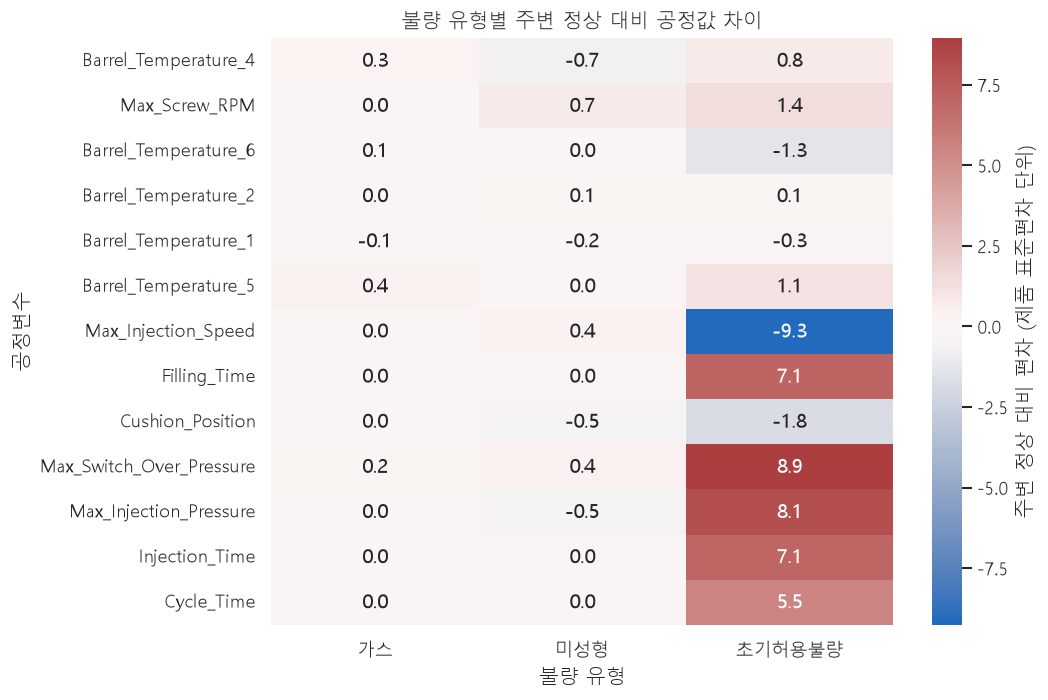

In [9]:
top_union = []
for reason in reason_order[1:]:
    part = local_summary[local_summary['불량유형'] == reason].head(6)
    top_union.extend(part['변수'].tolist())
top_union = list(dict.fromkeys(top_union))
heat = local_summary.pivot(index='변수', columns='불량유형', values='중앙편차').reindex(top_union)
heat = heat.reindex(columns=reason_order[1:])
fig, ax = plt.subplots(figsize=(9, max(6, len(heat)*0.38)))
sns.heatmap(heat, cmap='vlag', center=0, annot=True, fmt='.1f', ax=ax, cbar_kws={'label':'주변 정상 대비 편차 (제품 표준편차 단위)'})
ax.set_title('불량 유형별 주변 정상 대비 공정값 차이')
ax.set_xlabel('불량 유형')
ax.set_ylabel('공정변수')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'eda_reason_local_deviation_heatmap.png', bbox_inches='tight')
plt.show()

## 5. 쉬운 요약 보고서 생성

In [10]:
def association_lines(reason, n=6):
    part = association[(association['불량유형'] == reason) & (association['FDR_q값'] < 0.10)].head(n)
    lines = []
    for row in part.itertuples(index=False):
        direction = '높음' if row.상관계수 > 0 else '낮음'
        lines.append(f'- `{row.변수}`: 정상보다 {direction} (상관계수 {row.상관계수:+.2f}, 방향보정 AUC {row.방향보정AUC:.2f})')
    return lines

report = [
    '# 사출성형 데이터 EDA 쉬운 요약', '',
    '## 결론부터', '',
    '- 원본에는 불량이 두 종류가 아니라 세 종류로 기록되어 있다.',
    '- 가스 30건, 미성형 12건, 초기허용불량 10건이다.',
    '- 초기허용불량 10건은 대회용 2차 가공 CN7/RG3 파일에서는 빠져 있었다.',
    '- 따라서 불량 유형 분석은 참고용 원본 `moldset_labeled.csv`를 사용해야 한다.',
    '- 이 원본은 대회 제공본이 아니므로 분석 참고에는 사용하되, 모델 학습이나 제출물에 포함할 수 있는지는 대회 규정을 별도로 확인해야 한다.', '',
    '## 데이터 상태', '',
    '- 전체 2,607건 중 정상 2,555건, 불량 52건이다.',
    '- 공정변수 결측값은 없지만 불량 수가 적어서 결과는 원인 확정보다 점검 우선순위를 정하는 용도로 적합하다.', '',
    '## 가스 불량', ''
] + association_lines('가스') + [
    '', '가스 불량은 CN7과 RG3에 모두 있다. 형체 닫힘 시간, 가소화 위치, 금형온도가 조금 높은 경향이 있지만 상관계수는 작다. 즉 이 값 하나만으로 가스를 판단하기는 어렵다.', '',
    '## 미성형', ''
] + association_lines('미성형') + [
    '', '미성형도 CN7과 RG3에 모두 있다. 여러 변수 중 최대 사출속도가 높은 것이 가장 뚜렷했고, 나머지 변수는 표본 12건에서 통계적으로 확실하지 않았다.', '',
    '## 초기허용불량', ''
] + association_lines('초기허용불량') + [
    '', '초기허용불량 10건은 2020-10-27 00:56~01:05의 약 9분 구간에 몰려 있고 모두 CN7이다. 생산 시작 또는 조건 변경 직후의 세팅 문제와 일치하는 패턴이다.', '',
    '## 해석 방법', '',
    '- 값이 높거나 낮다고 해서 그 변수가 불량의 직접 원인이라고 확정할 수는 없다.',
    '- 서로 강하게 연결된 온도·압력·시간 변수가 함께 변했을 수 있다.',
    '- 먼저 표시된 상위 변수의 설비 설정 이력과 불량 발생 직전 변화량을 현장 기록과 대조하는 것이 좋다.',
    '- 가스 불량은 원재료 수분, 건조조건, 금형 배기 상태처럼 현재 파일에 없는 변수도 함께 확인해야 한다.'
]
report_path = REPORT_DIR / 'eda_easy_summary.md'
report_path.write_text('\n'.join(report), encoding='utf-8')
print('\n'.join(report))
print(f'\nSaved: {report_path}')

# 사출성형 데이터 EDA 쉬운 요약

## 결론부터

- 원본에는 불량이 두 종류가 아니라 세 종류로 기록되어 있다.
- 가스 30건, 미성형 12건, 초기허용불량 10건이다.
- 초기허용불량 10건은 대회용 2차 가공 CN7/RG3 파일에서는 빠져 있었다.
- 따라서 불량 유형 분석은 참고용 원본 `moldset_labeled.csv`를 사용해야 한다.
- 이 원본은 대회 제공본이 아니므로 분석 참고에는 사용하되, 모델 학습이나 제출물에 포함할 수 있는지는 대회 규정을 별도로 확인해야 한다.

## 데이터 상태

- 전체 2,607건 중 정상 2,555건, 불량 52건이다.
- 공정변수 결측값은 없지만 불량 수가 적어서 결과는 원인 확정보다 점검 우선순위를 정하는 용도로 적합하다.

## 가스 불량

- `Clamp_Close_Time`: 정상보다 높음 (상관계수 +0.08, 방향보정 AUC 0.69)
- `Plasticizing_Position`: 정상보다 높음 (상관계수 +0.07, 방향보정 AUC 0.67)
- `Mold_Temperature_4`: 정상보다 높음 (상관계수 +0.06, 방향보정 AUC 0.65)
- `Mold_Temperature_3`: 정상보다 높음 (상관계수 +0.05, 방향보정 AUC 0.65)

가스 불량은 CN7과 RG3에 모두 있다. 형체 닫힘 시간, 가소화 위치, 금형온도가 조금 높은 경향이 있지만 상관계수는 작다. 즉 이 값 하나만으로 가스를 판단하기는 어렵다.

## 미성형

- `Max_Injection_Speed`: 정상보다 높음 (상관계수 +0.14, 방향보정 AUC 0.68)

미성형도 CN7과 RG3에 모두 있다. 여러 변수 중 최대 사출속도가 높은 것이 가장 뚜렷했고, 나머지 변수는 표본 12건에서 통계적으로 확실하지 않았다.

## 초기허용불량

- `Max_Injection_Speed`: 정상보다 낮음 (상관계수 -0.57, 방향보정 AUC 1.00)
- `Filling_Time`: 정상보다 높음 (상관